# Notebook 5: Forecasting Project, Part 1: Data and Baselines
**Phase 3, Day 5**

No model is built today. The goal: load the data, understand it, split it correctly, build the window dataset and write down the **baseline scores**. Tomorrow the LSTM/GRU has to beat these scores.

In [1]:
!pip -q install yfinance

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

## Part 1: Loading the data
Change `DATA_SOURCE` to run the different experiments:
- `"stock"`: 5 years of daily closing prices from yfinance (set `TICKER` to a company of your choice).
- `"airline"`: monthly airline passengers (trend + seasonality, a dataset with real patterns).
- `"synthetic"`: an offline backup in case there is no internet.

It is easier to start with `"airline"`, then run `"stock"` as the second experiment.

In [3]:
DATA_SOURCE = "airline"     # "stock", "airline" or "synthetic"
TICKER = "AAPL"             # a company of your choice

def load_series(source):
    if source == "stock":
        import yfinance as yf
        df = yf.download(TICKER, period="5y", auto_adjust=True, progress=False)
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        s = df["Close"].dropna()
        return s, f"{TICKER} closing price"
    if source == "airline":
        import seaborn as sns
        f = sns.load_dataset("flights")
        idx = pd.to_datetime(f["year"].astype(str) + "-" + f["month"].astype(str), format="%Y-%b")
        return pd.Series(f["passengers"].values.astype(float), index=idx), "Airline passengers (monthly)"
    # synthetic: trend + seasonality + noise
    idx = pd.date_range("2015-01-01", periods=600, freq="D")
    t = np.arange(600)
    vals = 100 + 0.05 * t + 10 * np.sin(2 * np.pi * t / 30) + np.random.randn(600) * 2
    return pd.Series(vals, index=idx), "Synthetic series"

series, title = load_series(DATA_SOURCE)
print(title, "| points:", len(series))
print(series.head())

Airline passengers (monthly) | points: 144
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
dtype: float64


## Part 2: Understanding the data

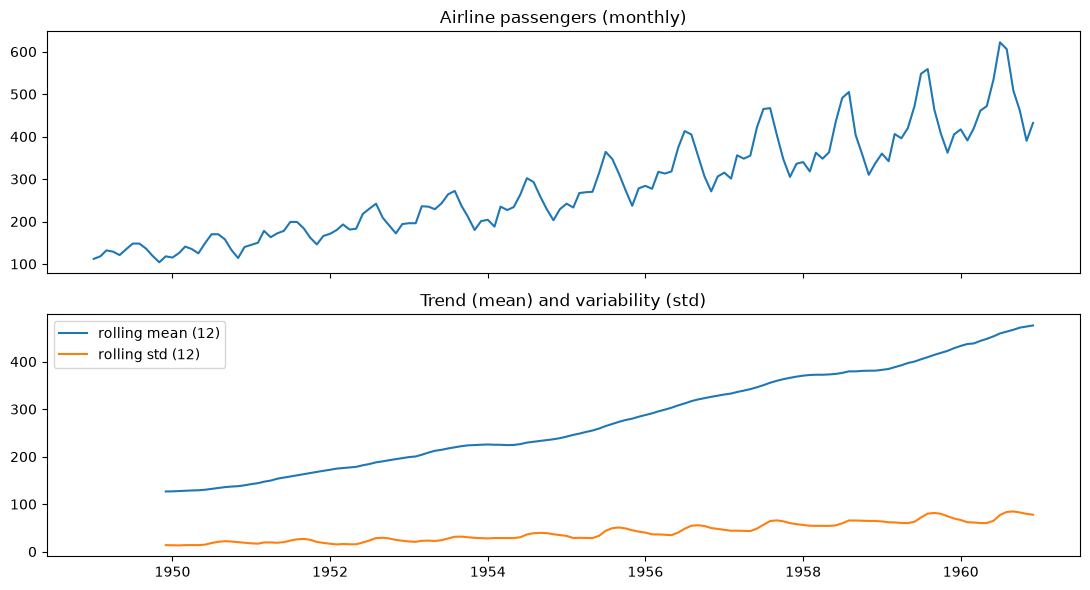

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(series.index, series.values)
ax[0].set_title(title)

win = 12 if DATA_SOURCE == "airline" else 30
ax[1].plot(series.index, series.rolling(win).mean(), label=f"rolling mean ({win})")
ax[1].plot(series.index, series.rolling(win).std(), label=f"rolling std ({win})")
ax[1].legend(); ax[1].set_title("Trend (mean) and variability (std)")
plt.tight_layout(); plt.show()

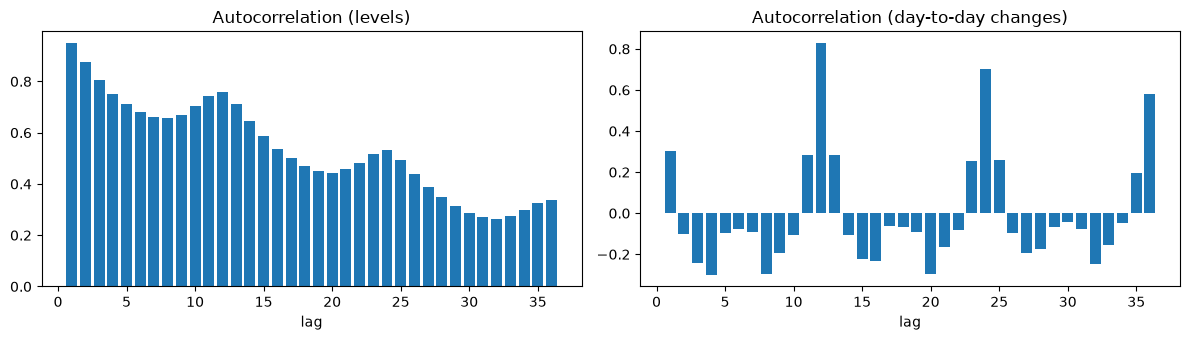

In [5]:
# Autocorrelation: how strongly is today's value related to past values?
def autocorr(x, max_lag):
    x = np.asarray(x) - np.mean(x)
    denom = np.sum(x ** 2)
    return np.array([np.sum(x[:-l] * x[l:]) / denom for l in range(1, max_lag + 1)])

max_lag = 36 if DATA_SOURCE == "airline" else 40
vals = series.values.astype(float)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(range(1, max_lag + 1), autocorr(vals, max_lag))
ax[0].set_title("Autocorrelation (levels)"); ax[0].set_xlabel("lag")
changes = np.diff(vals)
ax[1].bar(range(1, max_lag + 1), autocorr(changes, max_lag))
ax[1].set_title("Autocorrelation (day-to-day changes)"); ax[1].set_xlabel("lag")
plt.tight_layout(); plt.show()

**Observation (write in your own words):**
- Is there a trend? Is there seasonality (for airline data, every 12 months)?
- For stocks the autocorrelation of the changes is close to 0. That means yesterday's change does not predict today's, so the series behaves like a random walk. This is why it is hard for a model to beat the naive baseline on stock prices.

## Part 3: Time split, scaling and the window dataset
**Rules:**
1. No shuffling: train on the past, test on the future.
2. Scaling mean/std from the **training** part only.
3. The **target** of every window (the point to predict) must belong to the same split. Inputs of validation/test windows may contain values from the previous part (that is the past, so it is fine), but no target may appear in two splits.

train: 0..99 | val: 100..120 | test: 121..143
train/val/test windows: 88 21 23
Leakage check passed


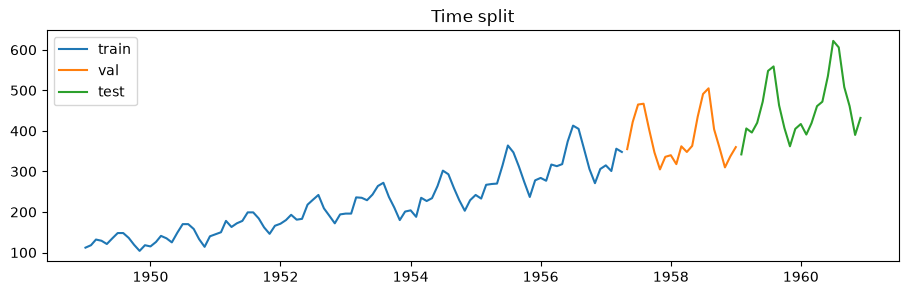

In [6]:
K = 12 if DATA_SOURCE == "airline" else 20      # window size
n = len(vals)
n_train, n_val = int(0.70 * n), int(0.15 * n)
print(f"train: 0..{n_train-1} | val: {n_train}..{n_train+n_val-1} | test: {n_train+n_val}..{n-1}")

# Scaling: from the training part only
mean, std = vals[:n_train].mean(), vals[:n_train].std()
scaled = (vals - mean) / std

# Build all windows; the index of the target tells us which split a window belongs to
X_all = np.array([scaled[i:i + K] for i in range(n - K)])
y_all = np.array([scaled[i + K] for i in range(n - K)])
target_idx = np.arange(K, n)

tr = target_idx < n_train
va = (target_idx >= n_train) & (target_idx < n_train + n_val)
te = target_idx >= n_train + n_val
X_train, y_train = X_all[tr], y_all[tr]
X_val,   y_val   = X_all[va], y_all[va]
X_test,  y_test  = X_all[te], y_all[te]
print("train/val/test windows:", len(X_train), len(X_val), len(X_test))

# Leakage check: no target appears in another split
assert target_idx[tr].max() < target_idx[va].min() < target_idx[va].max() < target_idx[te].min()
print("Leakage check passed")

dates = series.index[K:]
d_val, d_test = dates[va], dates[te]

plt.figure(figsize=(11, 3))
plt.plot(series.index[:n_train], vals[:n_train], label="train")
plt.plot(series.index[n_train:n_train + n_val], vals[n_train:n_train + n_val], label="val")
plt.plot(series.index[n_train + n_val:], vals[n_train + n_val:], label="test")
plt.legend(); plt.title("Time split"); plt.show()

## Part 4: Baselines
Scores are computed in **original units** (after un-scaling) so we can see what the error really is.

1. **Naive:** tomorrow = today.
2. **Moving average:** the mean of the last `M` values.
3. **Linear model:** linear regression on the last `K` values (fitted on the training part).
4. **Seasonal naive** (airline only): the value from the same month last year.

In [7]:
unscale = lambda a: a * std + mean
mae  = lambda a, b: np.mean(np.abs(a - b))
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))

def predict_baselines(X):
    """X: scaled windows (N, K). Predictions are in scaled space."""
    out = {}
    out["Naive"] = X[:, -1]
    M = 3 if DATA_SOURCE == "airline" else 5
    out[f"Moving avg ({M})"] = X[:, -M:].mean(axis=1)
    out["Linear (last K)"] = np.c_[X, np.ones(len(X))] @ w
    if DATA_SOURCE == "airline":
        out["Seasonal naive (12)"] = X[:, -12]     # K=12: first value of the window = 12 months earlier
    return out

# Linear model: fit on the training part (least squares)
A = np.c_[X_train, np.ones(len(X_train))]
w, *_ = np.linalg.lstsq(A, y_train, rcond=None)

rows = []
preds_val, preds_test = predict_baselines(X_val), predict_baselines(X_test)
real_val, real_test = unscale(y_val), unscale(y_test)
for name in preds_val:
    pv, pt = unscale(preds_val[name]), unscale(preds_test[name])
    rows.append({"Model": name,
                 "Val MAE": mae(real_val, pv), "Val RMSE": rmse(real_val, pv),
                 "Test MAE": mae(real_test, pt), "Test RMSE": rmse(real_test, pt)})

baseline_table = pd.DataFrame(rows).set_index("Model").round(3)
baseline_table

,Val MAE,Val RMSE,Test MAE,Test RMSE
Model,,,,
Naive,38.000,45.561,45.130,52.678
Moving avg (3),55.889,66.988,63.957,76.450
Linear (last K),19.325,24.709,12.425,16.139
Seasonal naive (12),24.952,31.039,48.783,50.891


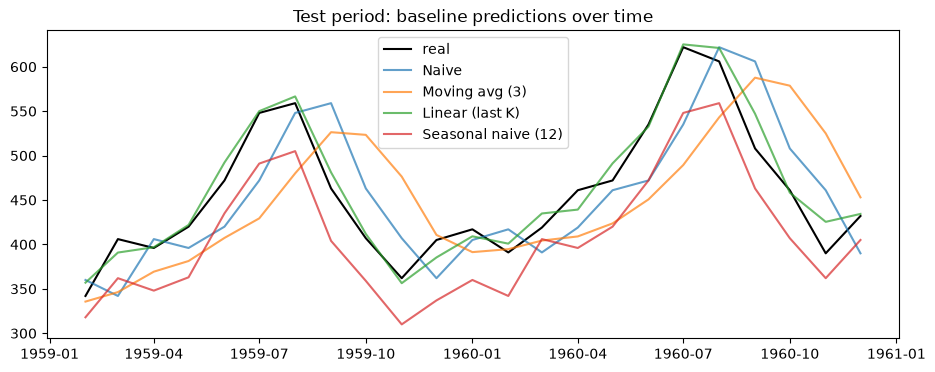

In [8]:
plt.figure(figsize=(11, 4))
plt.plot(d_test, real_test, label="real", color="black")
for name, p in preds_test.items():
    plt.plot(d_test, unscale(p), label=name, alpha=0.7)
plt.legend(); plt.title("Test period: baseline predictions over time")
plt.show()

**Observation:** which baseline is the best? Why do the naive predictions look one step behind the real series?

## Part 5: Saving the data for tomorrow (Day 6)

In [9]:
np.savez("prepared_data.npz",
         X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val,
         X_test=X_test, y_test=y_test, mean=mean, std=std, K=K,
         d_val=d_val.values, d_test=d_test.values)
baseline_table.to_csv("baseline_scores.csv")
print("Saved: prepared_data.npz, baseline_scores.csv")
print("\nThis is the score the LSTM/GRU has to beat:")
print(baseline_table[["Test MAE", "Test RMSE"]])

Saved: prepared_data.npz, baseline_scores.csv

This is the score the LSTM/GRU has to beat:
                     Test MAE  Test RMSE
Model                                   
Naive                  45.130     52.678
Moving avg (3)         63.957     76.450
Linear (last K)        12.425     16.139
Seasonal naive (12)    48.783     50.891


> Files in Colab disappear when the session ends. Work in the same session tomorrow, or download `prepared_data.npz` and `baseline_scores.csv`.

## Summary (write in your own words)
- Trend/seasonality in the data:
- The rules for splitting, scaling and leakage:
- The baseline scores (this table also goes into the README):
- My expectation: will the LSTM beat the naive baseline? (compare tomorrow)